# FX, all currencies: recalibrating Dynamic BPS vs the LDF pool

In [1]:
%load_ext autoreload
%autoreload 2

import os, pickle
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import norm

from ldf import ldf_func
from pit import pit_func
from utils.utils import ex_tlp
from uniformity_tests import uniformity_test
from recal_dma_new import (tvgas_pit_dma_new, convolution_recal_pit_dma_new, dm_test, _hac_lag,
                           _pit_quantiles, _IVL_PROBS, _MIN_TRAIN)
from recal_beta_dma_new import tvgas_pit_beta_dma_new, convolution_recal_pit_beta_dma_new
from localised_metrics import evaluate_localized, static_reports
import bps
import sim_report as sr

OUT = Path("figures/fx"); OUT.mkdir(parents=True, exist_ok=True)
RES_DIR = Path("results/bps_fx_results"); RES_DIR.mkdir(parents=True, exist_ok=True)
Path("tables").mkdir(parents=True, exist_ok=True)

## 0. Settings

In [2]:
CURRENCIES = ['AUD', 'CAD', 'EUR', 'JPY', 'NZD', 'NOK', 'SEK', 'CHF', 'GBP']
time_ind = 362                  # evaluation window (last time_ind months)

# ---- BPS (FX settings) ------------------------------------------------------------------
BPS_DELTA  = (0.99, 0.99)       # [state discount, obs. variance discount]
C0_SCALE   = 0.297              # C_0 = C0_SCALE * I
N0         = 1 / (1 - BPS_DELTA[1])
AGENT_DOF  = 1000.0             # Gaussian agents: a large t dof makes them numerically normal
BPS_MIN_TRAIN = 50
BURN_IN, MCMC_ITER = 3000, 8000 # quick test: 300, 500
EXACT_PORT, N_JOBS = True, -1

# ---- LDF comparison ---------------------------------------------------------------------
LDF_DELTA = 0.9

# ---- recalibration: the settings of fx_all_currencies.ipynb -----------------------------
K = 4
WARMUP = 60
EVAL_START = WARMUP + _MIN_TRAIN
ALPHA, FLOOR = 0.9, 1e-3
REFIT, HIDDEN, EPOCHS, LR, SEED = 80, 4, 200, 1e-3, 42
STATIC_REFIT = 80
MIN_EVENTS, N_BLOCKS = 30, 2    # localized regions on ~260 scored months

## 1. Data and the LDF weights (shared by all currencies)

In [3]:
exchange_rate = pd.read_excel(r"data/Y.xlsx", header=0, engine="openpyxl")
exchange_rate.rename(columns={"Unnamed: 0": "Date"}, inplace=True)
exchange_rate["Date"] = pd.to_datetime(exchange_rate["Date"])

log_lik    = np.load(r"data/uip_l1_save_loglik.npz")["x"]
means      = np.load(r"data/uip_l1_save_means.npz")["x"]
covariance = np.load(r"data/uip_l1_save_covariance.npz")["x"]

discount_factors = np.array([1, 0.99, 0.95, 0.9, 0.8, 0.7, 0.6, 0.5, 0.4, 0.3, 0.2, 0.001])
res_ldf = ldf_func(log_lik.astype(float), levels=2, discount_factors=[discount_factors, discount_factors],
                   activation_functions=["softmax", "softmax"], c=1e-20)
d_idx = int(np.argmin(np.abs(discount_factors - LDF_DELTA)))
weights_win = res_ldf["weights"][:, -time_ind:, :]
print("agents:", means.shape[0], "| months:", means.shape[1])

agents: 32 | months: 362


## 2. One currency: pools, BPS, recalibration, tests, localized metrics

In [4]:
def _gauss_mix_logscore(mean, var, w, y):
    comp = norm.pdf(y[None, :], loc=mean, scale=np.sqrt(var))
    return np.log(np.clip(np.einsum("ptk,kt->pt", w, comp), 1e-300, None))


def _tests(pits, label):
    df = uniformity_test(np.atleast_2d(pits), discount_factors=label)[1]
    cols = [("KS_Test", "KS"), ("AD_Test", "AD"), ("Chi2_Test", "chi2"), ("DH_Test", "DH"),
            ("LB_Test", "LB"), ("Berkowitz_Test", "Berk")]
    return {lab: str(df[c].iloc[0]).strip().upper() == "PASS" for c, lab in cols}


def _intervals(cdfs, x, taus, y, sl):
    q = np.array([_pit_quantiles(cdfs[t], x, taus[t], _IVL_PROBS) for t in range(len(y))])
    lo, hi, yy = q[sl, 0], q[sl, 1], y[sl]
    return float(np.mean((yy >= lo) & (yy <= hi))), float(np.mean(hi - lo))


def run_currency(ccy):
    path = RES_DIR / f"{ccy}.pkl"
    if path.exists():
        return pickle.load(open(path, "rb"))
    ci = exchange_rate.columns.get_loc(ccy) - 1
    mean_all, var_all = means[:, :, ci], covariance[:, :, ci, ci]
    T_all = mean_all.shape[1]
    y_all = exchange_rate[ccy].values[-T_all:].astype(float)
    dates_win = pd.to_datetime(exchange_rate["Date"][-time_ind:]).reset_index(drop=True)
    m_w, v_w = mean_all[:, -time_ind:], var_all[:, -time_ind:]
    y_w = exchange_rate[ccy][-time_ind:].values.astype(float)

    s_y = y_all.std()
    x_grid = np.linspace(y_all.min() - 10 * s_y, y_all.max() + 10 * s_y, 2001)

    # ---- LDF pool --------------------------------------------------------------------
    lp = ex_tlp(m_w, v_w, x_grid, weights_win)            # (12, T, M)
    lp_pit = pit_func(lp, x_grid, y_w)
    lp_log = _gauss_mix_logscore(m_w, v_w, weights_win, y_w)

    # ---- BPS (cached separately: the slow part) ---------------------------------------
    bps_path = Path(f"results/bps_fx_{ccy}_{BURN_IN}_{MCMC_ITER}.pkl")
    start = max(BPS_MIN_TRAIN, T_all - time_ind)
    if bps_path.exists():
        bo = pickle.load(open(bps_path, "rb"))
    else:
        prior = dict(m_0=np.r_[0.0, np.full(mean_all.shape[0], 1.0 / mean_all.shape[0])],
                     C_0=C0_SCALE * np.eye(mean_all.shape[0] + 1), n_0=N0,
                     s_0=float(np.var(y_all[:start])))
        bo = bps.run_bps(y_all, mean_all.T, var_all.T, np.full((T_all, mean_all.shape[0]), AGENT_DOF),
                         x_grid, start=start, delta=BPS_DELTA, prior=prior, burn_in=BURN_IN,
                         mcmc_iter=MCMC_ITER, seed=42, n_jobs=N_JOBS, exact_port=EXACT_PORT)
        pickle.dump(bo, open(bps_path, "wb"))

    # ---- common window: the months BPS forecasts --------------------------------------
    off = start - (T_all - time_ind)
    W = slice(off, None)
    y = y_w[off:]
    dates = dates_win[off:].reset_index(drop=True)
    pools = {
        "LDF": dict(cdfs=lp[d_idx:d_idx + 1, W], pits=lp_pit[d_idx:d_idx + 1, W],
                    log=lp_log[d_idx:d_idx + 1, W],
                    mean=(m_w * weights_win[d_idx].T).sum(axis=0)[W], label=[float(LDF_DELTA)]),
        "BPS": dict(cdfs=bo["cdfs"], pits=pit_func(bo["cdfs"], x_grid, y), log=bo["log_pd"],
                    mean=bo["mean"][0], label=[float(BPS_DELTA[0])]),
    }
    sl = slice(EVAL_START, len(y))

    out = dict(ccy=ccy, dates=dates, y=y, pools={}, n=len(y) - EVAL_START)
    for name, P in pools.items():
        common = dict(x=x_grid, y=y, pit_data=P["pits"], cdf_data=P["cdfs"], discount_factors=P["label"],
                      warmup=WARMUP, eval_start=EVAL_START, alpha=ALPHA, floor=FLOOR)
        net = dict(refit_every=REFIT, hidden_size=HIDDEN, num_epochs=EPOCHS, learning_rate=LR, seed=SEED)
        R = dict(
            rg=tvgas_pit_dma_new(K=K, **common, static_baseline=True, static_refit_every=STATIC_REFIT, verbose=False),
            rc=convolution_recal_pit_dma_new(K=K, **common, **net, verbose=False),
            bg=tvgas_pit_beta_dma_new(**common, static_baseline=True, static_refit_every=STATIC_REFIT, verbose=False),
            bc=convolution_recal_pit_beta_dma_new(**common, **net, verbose=False))
        S = {"rs": static_reports(R["rg"], "rqs", K=K), "bs": static_reports(R["bg"], "beta")}

        # per-period log-score gain over the raw pool, for every model
        gain = {m: np.asarray(R[m][0]["log_likelihood"], float) for m in R}
        gain.update({m: np.asarray(S[m][0]["log_likelihood"], float) for m in S})
        # PITs on the scored window
        u = np.asarray(P["pits"][0], float)
        pits = {"raw": u[sl]}
        pits.update({m: np.asarray(R[m][0]["calibrated_pits"], float) for m in R})
        pits.update({m: np.asarray(S[m][0]["v_transformed"], float)[sl] for m in S})
        # 90% intervals: raw, methods, static maps
        cdf = P["cdfs"][0]
        ivl = {"raw": _intervals(cdf, x_grid, np.tile(sr_un, (len(y), 1)), y, sl)}
        for m in R:
            ivl[m] = _intervals(cdf, x_grid, np.asarray(R[m][0]["tau_grid"]), y, sl)
        for m in S:
            ivl[m] = _intervals(cdf, x_grid, S[m][0]["tau_grid"], y, sl)
        tests = {m: _tests(p, P["label"]) for m, p in pits.items()}
        loc = evaluate_localized(
            x=x_grid, y=y, pit_data=P["pits"], cdf_data=P["cdfs"],
            methods={"GAS spline": R["rg"], "CONV spline": R["rc"], "GAS beta": R["bg"], "CONV beta": R["bc"],
                     "Static spline": S["rs"], "Static beta": S["bs"]},
            discount_factor=P["label"][0], eval_start=EVAL_START,
            min_events=MIN_EVENTS, n_blocks=N_BLOCKS, verbose=False)
        entry = {"group": "", "localized": {}}
        tmp = {ccy: entry}
        sr.add_localized(tmp, ccy, loc)
        err = y[sl] - np.asarray(P["mean"])[sl]
        out["pools"][name] = dict(
            raw=dict(rmse=float(np.sqrt(np.mean(err ** 2))), logs=float(np.asarray(P["log"][0])[sl].mean()),
                     ks=float(stats.kstest(u[sl], "uniform").statistic),
                     ks_p=float(stats.kstest(u[sl], "uniform").pvalue)),
            gain=gain, pits=pits, ivl=ivl, tests=tests, localized=tmp[ccy])
    pickle.dump(out, open(path, "wb"))
    return out


from recal_dma_new import _UN as sr_un

In [5]:
%%time
RES = {}
for ccy in CURRENCIES:
    RES[ccy] = run_currency(ccy)
    print(f"{ccy}: done, {RES[ccy]['n']} scored months "
          f"({RES[ccy]['dates'].iloc[EVAL_START]:%Y-%m} to {RES[ccy]['dates'].iloc[-1]:%Y-%m})")

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 10 concurrent workers.
[Parallel(n_jobs=-1)]: Done   5 tasks      | elapsed:   58.2s
[Parallel(n_jobs=-1)]: Done  12 tasks      | elapsed:  1.8min
/opt/anaconda3/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
[Parallel(n_jobs=-1)]: Done  21 tasks      | elapsed:  2.7min
[Parallel(n_jobs=-1)]: Done  30 tasks      | elapsed:  3.0min
[Parallel(n_jobs=-1)]: Done  41 tasks      | elapsed:  4.8min
[Parallel(n_jobs=-1)]: Done  52 tasks      | elapsed:  6.1min
[Parallel(n_jobs=-1)]: Done  65 tasks      | elapsed:  7.8min
[Parallel(n_jobs=-1)]: Done  78 tasks      | elapsed:  9.7min
[Parallel(n_jobs=-1)]: Done  93 tasks      | elapsed: 12.8min
[Parallel(n_jobs=-1)]: Done 108 tasks      | elapsed: 15.3min
[Parallel(n_jobs=-1)]: Done 125 tasks      | elapse

AUD: done, 222 scored months (2002-02 to 2020-07)


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 10 concurrent workers.
[Parallel(n_jobs=-1)]: Done   5 tasks      | elapsed:   52.9s
[Parallel(n_jobs=-1)]: Done  12 tasks      | elapsed:  1.8min
[Parallel(n_jobs=-1)]: Done  21 tasks      | elapsed:  2.7min
[Parallel(n_jobs=-1)]: Done  30 tasks      | elapsed:  3.1min
/opt/anaconda3/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
[Parallel(n_jobs=-1)]: Done  41 tasks      | elapsed:  5.1min
[Parallel(n_jobs=-1)]: Done  52 tasks      | elapsed:  6.5min
[Parallel(n_jobs=-1)]: Done  65 tasks      | elapsed:  8.2min
[Parallel(n_jobs=-1)]: Done  78 tasks      | elapsed: 10.4min
[Parallel(n_jobs=-1)]: Done  93 tasks      | elapsed: 13.5min
[Parallel(n_jobs=-1)]: Done 108 tasks      | elapsed: 16.4min
[Parallel(n_jobs=-1)]: Done 125 tasks      | elapse

CAD: done, 222 scored months (2002-02 to 2020-07)


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 10 concurrent workers.
[Parallel(n_jobs=-1)]: Done   5 tasks      | elapsed:   45.0s
[Parallel(n_jobs=-1)]: Done  12 tasks      | elapsed:  1.6min
[Parallel(n_jobs=-1)]: Done  21 tasks      | elapsed:  2.5min
[Parallel(n_jobs=-1)]: Done  30 tasks      | elapsed:  2.9min
[Parallel(n_jobs=-1)]: Done  41 tasks      | elapsed:  4.8min
/opt/anaconda3/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
[Parallel(n_jobs=-1)]: Done  52 tasks      | elapsed:  6.3min
[Parallel(n_jobs=-1)]: Done  65 tasks      | elapsed:  8.1min
[Parallel(n_jobs=-1)]: Done  78 tasks      | elapsed: 10.0min
[Parallel(n_jobs=-1)]: Done  93 tasks      | elapsed: 13.0min
[Parallel(n_jobs=-1)]: Done 108 tasks      | elapsed: 15.7min
[Parallel(n_jobs=-1)]: Done 125 tasks      | elapse

EUR: done, 222 scored months (2002-02 to 2020-07)


... (6 outputs left out)

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 10 concurrent workers.
[Parallel(n_jobs=-1)]: Done   5 tasks      | elapsed:   36.6s
[Parallel(n_jobs=-1)]: Done  12 tasks      | elapsed:  1.2min
[Parallel(n_jobs=-1)]: Done  21 tasks      | elapsed:  1.9min
[Parallel(n_jobs=-1)]: Done  30 tasks      | elapsed:  2.1min
[Parallel(n_jobs=-1)]: Done  41 tasks      | elapsed:  3.6min
[Parallel(n_jobs=-1)]: Done  52 tasks      | elapsed:  4.6min
[Parallel(n_jobs=-1)]: Done  65 tasks      | elapsed:  5.8min
[Parallel(n_jobs=-1)]: Done  78 tasks      | elapsed:  7.2min
[Parallel(n_jobs=-1)]: Done  93 tasks      | elapsed:  9.5min
[Parallel(n_jobs=-1)]: Done 108 tasks      | elapsed: 11.6min
[Parallel(n_jobs=-1)]: Done 125 tasks      | elapsed: 14.4min
[Parallel(n_jobs=-1)]: Done 142 tasks      | elapsed: 17.4min
[Parallel(n_jobs=-1)]: Done 161 tasks      | elapsed: 21.2min
/opt/anaconda3/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stop

SEK: done, 222 scored months (2002-02 to 2020-07)


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 10 concurrent workers.
[Parallel(n_jobs=-1)]: Done   5 tasks      | elapsed:   30.0s
[Parallel(n_jobs=-1)]: Done  12 tasks      | elapsed:  1.0min
[Parallel(n_jobs=-1)]: Done  21 tasks      | elapsed:  1.6min
[Parallel(n_jobs=-1)]: Done  30 tasks      | elapsed:  1.9min
[Parallel(n_jobs=-1)]: Done  41 tasks      | elapsed:  3.2min
[Parallel(n_jobs=-1)]: Done  52 tasks      | elapsed:  4.1min
[Parallel(n_jobs=-1)]: Done  65 tasks      | elapsed:  5.3min
[Parallel(n_jobs=-1)]: Done  78 tasks      | elapsed:  6.6min
[Parallel(n_jobs=-1)]: Done  93 tasks      | elapsed:  8.7min
[Parallel(n_jobs=-1)]: Done 108 tasks      | elapsed: 10.6min
/opt/anaconda3/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
[Parallel(n_jobs=-1)]: Done 125 tasks      | elapse

CHF: done, 222 scored months (2002-02 to 2020-07)
GBP: done, 222 scored months (2002-02 to 2020-07)
CPU times: user 1min 41s, sys: 33 s, total: 2min 14s
Wall time: 9h 21min 30s


## 3. Raw pools: LDF vs BPS

In [6]:
rows = {}
for ccy, R in RES.items():
    for pool in ("LDF", "BPS"):
        r = R["pools"][pool]
        rows[(ccy, pool)] = {"RMSE": r["raw"]["rmse"], "mean LogS": r["raw"]["logs"],
                             "KS": r["raw"]["ks"], "KS p": r["raw"]["ks_p"],
                             "90% coverage": r["ivl"]["raw"][0], "90% width": r["ivl"]["raw"][1]}
RAW = pd.DataFrame(rows).T
RAW.style.format(precision=4)

In [7]:
def raw_latex(RAW, label="tab:bps-ldf-raw"):
    L = [r"\begin{table}[H]\centering\small",
         r"\begin{tabular}{l cccc cccc}\toprule",
         r" & \multicolumn{4}{c}{LDF} & \multicolumn{4}{c}{BPS} \\ \cmidrule(lr){2-5}\cmidrule(lr){6-9}",
         r"Currency & RMSE & LogS & KS & Cov. & RMSE & LogS & KS & Cov. \\ \midrule"]
    for ccy in CURRENCIES:
        cells = []
        for pool in ("LDF", "BPS"):
            r = RAW.loc[(ccy, pool)]
            ks = f"{r['KS']:.3f}" + (r"$^{\dagger}$" if r["KS p"] < 0.05 else "")
            cells += [f"{r['RMSE']:.4f}", f"{r['mean LogS']:.3f}", ks, f"{r['90% coverage']:.2f}"]
        L.append(f"{ccy} & " + " & ".join(cells) + r" \\")
    L += [r"\bottomrule\end{tabular}",
          r"\caption{Raw pools on the common BPS window: RMSE of the mean, mean log score, KS distance of the "
          r"PIT from uniform ($^\dagger$ rejects at 5\%) and coverage of the central 90\% interval.}",
          rf"\label{{{label}}}", r"\end{table}"]
    return "\n".join(L)

tex = raw_latex(RAW); print(tex); open("tables/bps_ldf_raw.tex", "w").write(tex)

\begin{table}[H]\centering\small
\begin{tabular}{l cccc cccc}\toprule
 & \multicolumn{4}{c}{LDF} & \multicolumn{4}{c}{BPS} \\ \cmidrule(lr){2-5}\cmidrule(lr){6-9}
Currency & RMSE & LogS & KS & Cov. & RMSE & LogS & KS & Cov. \\ \midrule
AUD & 0.0361 & 1.924 & 0.057 & 0.91 & 0.0362 & 1.914 & 0.083 & 0.92 \\
CAD & 0.0272 & 2.175 & 0.052 & 0.88 & 0.0270 & 2.185 & 0.079 & 0.92 \\
EUR & 0.0287 & 2.170 & 0.084 & 0.92 & 0.0281 & 2.138 & 0.108$^{\dagger}$ & 0.94 \\
JPY & 0.0265 & 2.198 & 0.083 & 0.93 & 0.0259 & 2.180 & 0.088 & 0.95 \\
NZD & 0.0381 & 1.870 & 0.065 & 0.91 & 0.0378 & 1.861 & 0.067 & 0.94 \\
NOK & 0.0346 & 1.929 & 0.036 & 0.87 & 0.0340 & 1.945 & 0.066 & 0.92 \\
SEK & 0.0332 & 1.999 & 0.055 & 0.91 & 0.0330 & 1.975 & 0.069 & 0.94 \\
CHF & 0.0307 & 2.099 & 0.087 & 0.93 & 0.0297 & 2.084 & 0.103$^{\dagger}$ & 0.96 \\
GBP & 0.0254 & 2.249 & 0.062 & 0.93 & 0.0254 & 2.220 & 0.084 & 0.96 \\
\bottomrule\end{tabular}
\caption{Raw pools on the common BPS window: RMSE of the mean, mean log scor

1146

## 4. Log-score gains per currency (HAC DM stars)

In [8]:
MODELS = [("rs", "Static RQS"), ("rg", "RQS-GAS"), ("rc", "RQS-Con"),
          ("bs", "Static Beta"), ("bg", "Beta-GAS"), ("bc", "Beta-Con")]


def dm_t(d):
    d = np.asarray(d, float)
    return dm_test(d, hac_lag=_hac_lag(len(d)))[2]


def stars(t):
    a = abs(t)
    return "" if not np.isfinite(t) else "***" if a > 2.576 else "**" if a > 1.96 else "*" if a > 1.645 else ""


G = {}
for ccy, R in RES.items():
    for pool in ("LDF", "BPS"):
        for m, lab in MODELS:
            d = R["pools"][pool]["gain"][m][EVAL_START:]
            G[(pool, ccy, lab)] = {"gain": d.mean(), "t": dm_t(d)}
G = pd.DataFrame(G).T
G["gain"].unstack().style.format("{:+.4f}")

In [9]:
def gains_latex(G, pool, label):
    L = [r"\begin{table}[H]\centering\small",
         r"\begin{tabular}{l" + "c" * len(MODELS) + r"}\toprule",
         "Currency & " + " & ".join(l for _, l in MODELS) + r" \\ \midrule"]
    for ccy in CURRENCIES:
        vals = {l: G.loc[(pool, ccy, l)] for _, l in MODELS}
        best = max(vals, key=lambda l: vals[l]["gain"])
        cells = []
        for _, l in MODELS:
            s = stars(vals[l]["t"]); body = f"{vals[l]['gain']:+.4f}" + (f"^{{{s}}}" if s else "")
            cells.append(rf"$\mathbf{{{body}}}$" if l == best else f"${body}$")
        L.append(f"{ccy} & " + " & ".join(cells) + r" \\")
    L += [r"\bottomrule\end{tabular}",
          rf"\caption{{Mean log-score gain per month over the raw {pool}, common BPS window, $\delta={LDF_DELTA}$ "
          r"for LDF. Stars: HAC Diebold--Mariano test at 10/5/1\%. Static: expanding-window static map of each "
          r"family. Best in bold.}", rf"\label{{{label}}}", r"\end{table}"]
    return "\n".join(L)

for pool in ("BPS", "LDF"):
    tex = gains_latex(G, pool, f"tab:fx-gains-{pool.lower()}")
    print(tex); open(f"tables/fx_gains_{pool.lower()}.tex", "w").write(tex)

\begin{table}[H]\centering\small
\begin{tabular}{lcccccc}\toprule
Currency & Static RQS & RQS-GAS & RQS-Con & Static Beta & Beta-GAS & Beta-Con \\ \midrule
AUD & $-0.0022$ & $+0.0018$ & $+0.0022$ & $-0.0158$ & $\mathbf{+0.0130}$ & $+0.0129$ \\
CAD & $-0.0091$ & $\mathbf{+0.0045}$ & $-0.0072$ & $-0.0036$ & $-0.0019$ & $-0.0020$ \\
EUR & $+0.0221$ & $+0.0301^{*}$ & $+0.0303$ & $+0.0057$ & $\mathbf{+0.0513^{**}}$ & $+0.0441^{**}$ \\
JPY & $+0.0015$ & $+0.0247$ & $+0.0238$ & $+0.0190$ & $\mathbf{+0.0507^{***}}$ & $+0.0498^{**}$ \\
NZD & $-0.0164$ & $-0.0148$ & $-0.0378^{***}$ & $\mathbf{-0.0000}$ & $-0.0006$ & $-0.0007$ \\
NOK & $-0.0079$ & $\mathbf{+0.0062}$ & $-0.0066$ & $-0.0243$ & $-0.0081$ & $-0.0162$ \\
SEK & $-0.0437$ & $-0.0032$ & $-0.0040$ & $-0.0087$ & $\mathbf{+0.0166}$ & $-0.0263$ \\
CHF & $+0.0256$ & $+0.0136$ & $+0.0149$ & $+0.0075$ & $\mathbf{+0.0430^{**}}$ & $+0.0429^{**}$ \\
GBP & $-0.0111$ & $+0.0087$ & $+0.0055$ & $-0.0314$ & $+0.0177$ & $\mathbf{+0.0192}$ \\
\bottomrule

In [10]:
# summary across currencies: significant gains / losses, coverage, width
crit = 1.96
summ = {}
for pool in ("LDF", "BPS"):
    for m, lab in MODELS:
        g = G.loc[pool].xs(lab, level=1)
        cov = np.mean([RES[c]["pools"][pool]["ivl"][m][0] for c in CURRENCIES])
        wid = np.mean([RES[c]["pools"][pool]["ivl"][m][1] / RES[c]["pools"][pool]["ivl"]["raw"][1] for c in CURRENCIES])
        summ[(pool, lab)] = {"LogS +": int((g["t"] > crit).sum()), "LogS -": int((g["t"] < -crit).sum()),
                             "mean gain": g["gain"].mean(), "coverage": cov, "width/raw": wid}
SUMM = pd.DataFrame(summ).T
SUMM.style.format(precision=3)

## 5. Calibration tests per currency

In [11]:
UNI = ["KS", "AD", "chi2", "DH"]
SHOW = [("raw", "Raw pool")] + MODELS


def tests_table(pool):
    return pd.DataFrame({lab: {c: sum(RES[c]["pools"][pool]["tests"][m][t] for t in UNI) for c in CURRENCIES}
                         for m, lab in SHOW}).T


def tests_latex(pool, label):
    tab = tests_table(pool)
    L = [r"\begin{table}[H]\centering\small",
         r"\begin{tabular}{l" + "c" * len(CURRENCIES) + r"}\toprule",
         "Method & " + " & ".join(CURRENCIES) + r" \\ \midrule"]
    for k, (m, lab) in enumerate(SHOW):
        if k in (1, 4):
            L.append(r"\midrule")
        L.append(f"{lab} & " + " & ".join(str(int(tab.loc[lab, c])) for c in CURRENCIES) + r" \\")
    L += [r"\bottomrule\end{tabular}",
          rf"\caption{{{pool}: number of the four uniformity tests (KS, Anderson--Darling, $\chi^2$, "
          r"Dawid--Sebastiani) that do not reject at 5\% for each currency.}",
          rf"\label{{{label}}}", r"\end{table}"]
    return "\n".join(L)

for pool in ("BPS", "LDF"):
    tex = tests_latex(pool, f"tab:fx-tests-{pool.lower()}")
    print(tex); open(f"tables/fx_tests_{pool.lower()}.tex", "w").write(tex)
tests_table("BPS")

\begin{table}[H]\centering\small
\begin{tabular}{lccccccccc}\toprule
Method & AUD & CAD & EUR & JPY & NZD & NOK & SEK & CHF & GBP \\ \midrule
Raw pool & 2 & 3 & 0 & 1 & 3 & 3 & 4 & 0 & 1 \\
\midrule
Static RQS & 3 & 3 & 3 & 4 & 4 & 4 & 4 & 3 & 4 \\
RQS-GAS & 3 & 3 & 4 & 4 & 4 & 4 & 4 & 3 & 3 \\
RQS-Con & 3 & 3 & 4 & 4 & 4 & 4 & 4 & 3 & 4 \\
\midrule
Static Beta & 2 & 3 & 3 & 3 & 3 & 2 & 4 & 3 & 3 \\
Beta-GAS & 4 & 3 & 4 & 4 & 4 & 4 & 4 & 3 & 3 \\
Beta-Con & 4 & 3 & 4 & 4 & 4 & 4 & 4 & 3 & 3 \\
\bottomrule\end{tabular}
\caption{BPS: number of the four uniformity tests (KS, Anderson--Darling, $\chi^2$, Dawid--Sebastiani) that do not reject at 5\% for each currency.}
\label{tab:fx-tests-bps}
\end{table}
\begin{table}[H]\centering\small
\begin{tabular}{lccccccccc}\toprule
Method & AUD & CAD & EUR & JPY & NZD & NOK & SEK & CHF & GBP \\ \midrule
Raw pool & 3 & 3 & 2 & 1 & 3 & 4 & 4 & 2 & 3 \\
\midrule
Static RQS & 3 & 3 & 3 & 3 & 4 & 4 & 4 & 3 & 3 \\
RQS-GAS & 3 & 3 & 3 & 4 & 4 & 4 & 4 & 3 &

,AUD,CAD,EUR,JPY,NZD,NOK,SEK,CHF,GBP
Raw pool,2,3,0,1,3,3,4,0,1
Static RQS,3,3,3,4,4,4,4,3,4
RQS-GAS,3,3,4,4,4,4,4,3,3
RQS-Con,3,3,4,4,4,4,4,3,4
Static Beta,2,3,3,3,3,2,4,3,3
Beta-GAS,4,3,4,4,4,4,4,3,3
Beta-Con,4,3,4,4,4,4,4,3,3


## 6. Gain vs raw miscalibration, LDF and BPS

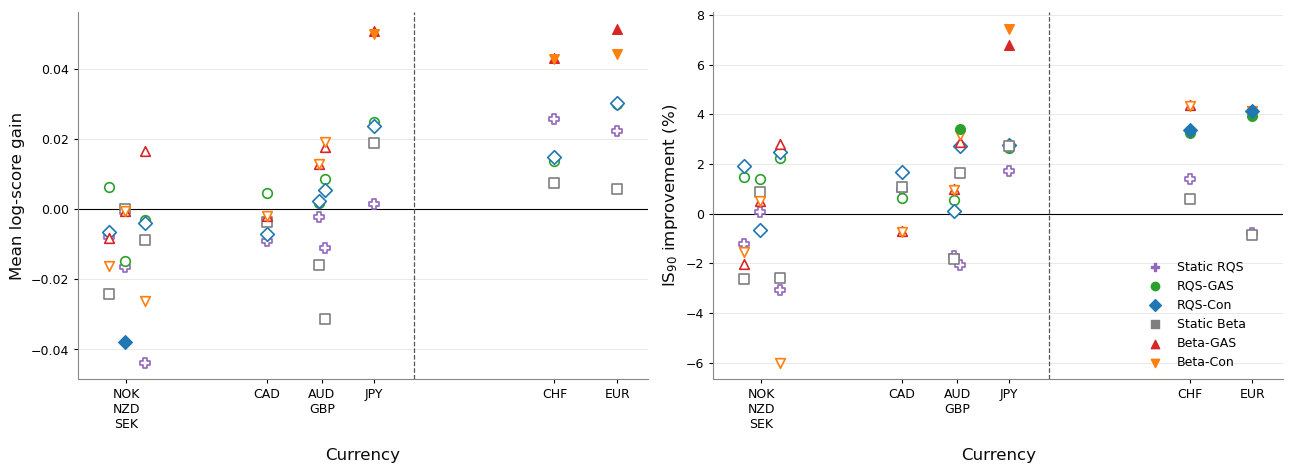

In [24]:
colors = {"Static RQS": "#9467bd", "Static Beta": "#7f7f7f", "RQS-GAS": "#2ca02c", "RQS-Con": "#1f77b4",
          "Beta-GAS": "#d62728", "Beta-Con": "#ff7f0e"}
markers = {"Static RQS": "P", "Static Beta": "s", "RQS-GAS": "o", "RQS-Con": "D", "Beta-GAS": "^", "Beta-Con": "v"}
KEY = {"Static RQS": "rs", "RQS-GAS": "rg", "RQS-Con": "rc", "Static Beta": "bs", "Beta-GAS": "bg", "Beta-Con": "bc"}
POOL = "BPS"


def is90_improvement(ccy, lab):
    """BPS 90% interval-score improvement over the raw pool (%), and whether the HAC test is
    significant at 5% (two or more stars), from the stored localized results."""
    loc = next(iter(RES[ccy]["pools"][POOL]["localized"]["localized"].values()))
    row = loc["is90"]
    raw, lev = row["raw"], row["level"][KEY[lab]]
    g = str(row["gain"][KEY[lab]]).strip()
    n_stars = len(g) - len(g.rstrip("*"))
    return 100 * (raw - lev) / raw, n_stars >= 2


xs = np.array([RES[c]["pools"][POOL]["raw"]["ks"] for c in CURRENCIES])
crit_ks = 1.36 / np.sqrt(RES[CURRENCIES[0]]["n"])
span = xs.max() - xs.min()
xlo = min(xs.min(), crit_ks) - 0.06 * span
xhi = max(xs.max(), crit_ks) + 0.06 * span

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharex=True)
for ax, panel in zip(axes, ("logs", "is90")):
    for _, lab in MODELS:
        if panel == "logs":
            ys = np.array([G.loc[(POOL, c, lab), "gain"] for c in CURRENCIES])
            sig = np.abs(np.array([G.loc[(POOL, c, lab), "t"] for c in CURRENCIES])) > crit
        else:
            vals = [is90_improvement(c, lab) for c in CURRENCIES]
            ys = np.array([v[0] for v in vals]); sig = np.array([v[1] for v in vals])
        rho = stats.spearmanr(xs, ys)[0]
        ax.scatter(xs[~sig], ys[~sig], marker=markers[lab], facecolors="white", edgecolors=colors[lab],
                   s=48, lw=1.2, zorder=3)
        ax.scatter(xs[sig], ys[sig], marker=markers[lab], color=colors[lab], s=48, zorder=4)
        ax.scatter([], [], marker=markers[lab], color=colors[lab], label=f"{lab}")#  (ρ = {rho:+.2f})")
    ax.axhline(0, color="black", lw=0.8)
    ax.axvline(crit_ks, color="#555555", lw=0.9, ls="--")
    ax.set_xlim(xlo, xhi)
    currency_ticks(ax, xs, CURRENCIES)
    ax.tick_params(axis="both", length=3, color="black", labelcolor="black")
    ax.set_xlabel("Currency", labelpad=12,fontsize=12)
    ax.set_ylabel("Mean log-score gain" if panel == "logs" else r'$\mathrm{IS}_{90}$ improvement (%)',fontsize=12)
    #ax.legend(fontsize=9, frameon=False, loc="upper left")
    ax.grid(axis="y", color="#e6e5e1", lw=0.6)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
        
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, ncol=1, frameon=False, fontsize=9, loc='lower right', bbox_to_anchor=(0.97, 0.2))
fig.tight_layout()
fig.savefig(OUT / "bps_gain_vs_miscalibration.pdf", bbox_inches="tight")
plt.show()

## 7. Localized scorecards (all scores, static maps included)

In [13]:
d = sr.DELTAS.index(LDF_DELTA)
for pool in ("BPS", "LDF"):
    entries = {c: RES[c]["pools"][pool]["localized"] for c in CURRENCIES}
    if pool == "BPS":      # BPS results are stored under the BPS discount factor
        entries = {c: {"group": "", "localized": {round(float(LDF_DELTA), 6): next(iter(e["localized"].values()))}}
                   for c, e in entries.items()}
    tex = sr.scorecard_latex(entries, d, caption=(
        rf"{pool}, common BPS window. KS: Kolmogorov--Smirnov distance of the PIT from uniform ($^\dagger$ rejects "
        r"at 5\%). Raw pool: level of each score; method columns: gain over the raw pool, positive is better. "
        r"Stars: HAC Giacomini--White test at 10/5/1\%. Static RQS, Static Beta: expanding-window static maps. "
        r"Best method in bold."))
    tex = tex.replace(r"\label{tab:sim_scorecard}", rf"\label{{tab:fx-scores-{pool.lower()}}}")
    print(tex); open(f"tables/fx_scores_{pool.lower()}.tex", "w").write(tex)

\begin{table}[H]\centering\small
\begin{tabular}{llccccccc}\toprule
Scenario & Metric & Raw pool & Static RQS & RQS-GAS & RQS-Con & Static Beta & Beta-GAS & Beta-Con \\ \midrule
AUD & KS & $0.083$ & $0.046$ & $\mathbf{0.036}$ & $0.037$ & $0.059$ & $0.046$ & $0.047$ \\
 & LogS & $1.9137$ & $-0.0022$ & $+0.0018$ & $+0.0022$ & $-0.0158$ & $\mathbf{+0.0130}$ & $+0.0129$ \\
 & CRPS & $0.0198$ & $-0.0000$ & $\mathbf{+0.0001}$ & $+0.0001$ & $+0.0000$ & $+0.0001$ & $+0.0001$ \\
 & IS$_{90}$ & $0.1567$ & $-0.0026$ & $+0.0009$ & $+0.0002$ & $-0.0029$ & $\mathbf{+0.0015}$ & $+0.0015$ \\
 & IS$_{95}$ & $0.1838$ & $-0.0057$ & $\mathbf{+0.0040^{**}}$ & $+0.0035$ & $-0.0056$ & $+0.0018$ & $+0.0017$ \\
 & CSL$_{L}$ & $-0.0681$ & $-0.0034$ & $+0.0126$ & $\mathbf{+0.0141^{*}}$ & $-0.0117$ & $+0.0047$ & $+0.0046$ \\
 & CSL$_{R}$ & $0.0614$ & $-0.0033$ & $+0.0020$ & $\mathbf{+0.0024}$ & $-0.0053$ & $+0.0002$ & $+0.0002$ \\
\addlinespace
CAD & KS & $0.079$ & $0.051$ & $0.041$ & $\mathbf{0.037}$ & $0.041$ &